# KNN model: heart disease risk from BRFSS 2022

Target is `HadHeartAttack` (Yes/No), roughly 5-6% positive. This notebook trains a k-nearest-neighbors classifier, tunes it, and evaluates on the held-out test set with ROC-AUC, PR-AUC, F1, precision, recall and a confusion matrix. Same split, metrics and threshold rule as `xgboost_model.ipynb`, so the numbers are directly comparable.

Plan:
1. load, drop rows with no label, split 60/20/20 (same seed and stratification as the EDA notebook)
2. encode features, then impute / one-hot / scale (KNN needs all three)
3. handle the class imbalance with resampling, since KNN has no `class_weight`
4. tune k, weights and the resampling strategy with cross-validation on a stratified subset of the training set
5. refit on the full training set, pick a threshold on validation, report once on test

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve,
                             roc_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

warnings.filterwarnings("ignore", category=UserWarning)
# imbalanced-learn calls a few scikit-learn internals that are being renamed; harmless, but noisy.
# The environment variable silences it in the parallel CV workers too.
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
pd.set_option("display.max_columns", 50)

SEED = 42
DATA_PATH = "../Data/heart_2022_with_nans.csv"
TARGET = "HadHeartAttack"

### 1. Load and split

In [2]:
with open(DATA_PATH, encoding="utf-8") as f:
    if f.readline().startswith("version https://git-lfs"):
        raise RuntimeError("Data file is a Git LFS pointer. Run `git lfs pull` first.")

df = pd.read_csv(DATA_PATH)
print("raw shape:", df.shape)

# rows with no label can't be used for training or scoring
df = df[df[TARGET].notna()].reset_index(drop=True)
y = (df[TARGET] == "Yes").astype(int)
X_raw = df.drop(columns=[TARGET])

print("after dropping unlabeled:", df.shape)
print(f"positive rate: {y.mean():.2%}")

raw shape: (445132, 40)


after dropping unlabeled: (442067, 40)
positive rate: 5.68%


In [3]:
# 60 / 20 / 20, stratified so the positive rate matches in every split
X_tmp, X_test_raw, y_tmp, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:<6}{len(part):>8,} rows   positive rate {part.mean():.2%}")

train  265,239 rows   positive rate 5.68%
val     88,414 rows   positive rate 5.68%
test    88,414 rows   positive rate 5.68%


### 2. Encoding, missing values and scaling

KNN predicts from distances between rows, so unlike XGBoost it can't take `NaN` or text, and every column has to be on a comparable scale.

- same fixed encoding as the XGBoost notebook: Yes/No -> 1/0, ordinal columns get an integer order, age category -> lower bound of the bracket, plus the engineered counts
- `State` is dropped (54 levels would add 54 one-hot dimensions and swamp the distance)
- continuous columns are capped at the 0.5th / 99.5th percentile of the training rows first, otherwise a few extreme weights or BMIs squash everyone else into a tiny range after MinMax scaling
- missing values: median for numeric / ordinal, most frequent for Yes/No, an explicit `"Missing"` level for the categoricals
- everything is scaled to 0-1 (MinMax) so the 0/1 columns and the numeric columns count roughly equally

All of these learn their statistics in `fit()`, and the preprocessor sits inside the model pipeline, so during cross-validation it is re-fit on each training fold only.

In [4]:
YES_NO = ["PhysicalActivities", "HadAngina", "HadStroke", "HadAsthma", "HadSkinCancer",
          "HadCOPD", "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis",
          "DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
          "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands",
          "ChestScan", "AlcoholDrinkers", "HIVTesting", "FluVaxLast12",
          "PneumoVaxEver", "HighRiskLastYear"]

ORDINAL = {
    "GeneralHealth": {"Poor": 0, "Fair": 1, "Good": 2, "Very good": 3, "Excellent": 4},
    "RemovedTeeth": {"None of them": 0, "1 to 5": 1, "6 or more, but not all": 2, "All": 3},
    "LastCheckupTime": {
        "Within past year (anytime less than 12 months ago)": 0,
        "Within past 2 years (1 year but less than 2 years ago)": 1,
        "Within past 5 years (2 years but less than 5 years ago)": 2,
        "5 or more years ago": 3},
    "SmokerStatus": {
        "Never smoked": 0, "Former smoker": 1,
        "Current smoker - now smokes some days": 2,
        "Current smoker - now smokes every day": 3},
    "ECigaretteUsage": {
        "Never used e-cigarettes in my entire life": 0, "Not at all (right now)": 1,
        "Use them some days": 2, "Use them every day": 3},
}

CAT_COLS = ["HadDiabetes", "RaceEthnicityCategory", "TetanusLast10Tdap", "CovidPos"]

CHRONIC = ["HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD",
           "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis"]
DISABILITY = ["DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
              "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands"]

CONTINUOUS = ["PhysicalHealthDays", "MentalHealthDays", "SleepHours",
              "HeightInMeters", "WeightInKilograms", "BMI"]
ORDERED = list(ORDINAL) + ["AgeCategory", "chronic_count", "disability_count", "n_missing"]
BINARY = ["Sex", "diabetes_yes"] + YES_NO


def encode(raw):
    """Fixed-rule encoding (learns nothing from the data), applied the same way to every split."""
    X = raw.drop(columns=["State"]).copy()

    for c in YES_NO:
        X[c] = raw[c].map({"Yes": 1.0, "No": 0.0})
    X["Sex"] = raw["Sex"].map({"Male": 1.0, "Female": 0.0})
    for c, order in ORDINAL.items():
        X[c] = raw[c].map(order)
    X["AgeCategory"] = raw["AgeCategory"].str.extract(r"(\d+)", expand=False).astype(float)

    # BMI is missing for some rows where height and weight are both there
    X["BMI"] = raw["BMI"].fillna(raw["WeightInKilograms"] / raw["HeightInMeters"] ** 2)
    X["chronic_count"] = X[CHRONIC].sum(axis=1)
    X["diabetes_yes"] = (raw["HadDiabetes"] == "Yes").astype(float)
    X["disability_count"] = X[DISABILITY].sum(axis=1)
    X["n_missing"] = raw.isna().sum(axis=1)
    return X


X_train = encode(X_train_raw)
X_val = encode(X_val_raw)
X_test = encode(X_test_raw)

assert sorted(CONTINUOUS + ORDERED + BINARY + CAT_COLS) == sorted(X_train.columns), \
    set(X_train.columns).symmetric_difference(CONTINUOUS + ORDERED + BINARY + CAT_COLS)
print(X_train.shape)
X_train.isna().mean().sort_values(ascending=False).head(8).round(3)

(265239, 42)


TetanusLast10Tdap    0.185
PneumoVaxEver        0.172
HIVTesting           0.148
ChestScan            0.125
CovidPos             0.113
HighRiskLastYear     0.113
FluVaxLast12         0.105
AlcoholDrinkers      0.104
dtype: float64

In [5]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Caps each column at quantiles learned in fit() (the training rows). NaN stays NaN."""

    def __init__(self, lower=0.005, upper=0.995):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(values, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(values, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_bounds_, self.upper_bounds_)


def make_preprocessor():
    return ColumnTransformer([
        ("continuous", Pipeline([("clip", QuantileClipper()),
                                 ("impute", SimpleImputer(strategy="median")),
                                 ("scale", MinMaxScaler())]), CONTINUOUS),
        ("ordered", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", MinMaxScaler())]), ORDERED),
        ("binary", SimpleImputer(strategy="most_frequent"), BINARY),
        ("categorical", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
         CAT_COLS),
    ])


# how many dimensions the distance is computed over
n_dims = make_preprocessor().fit(X_train).transform(X_val.head(5)).shape[1]
print("features after preprocessing:", n_dims)

features after preprocessing: 58


### 3. Class imbalance and a tuning subset

KNN's `fit` has no `class_weight` or `sample_weight`, so the imbalance is handled by resampling the training rows instead. Three options get compared during tuning:

- **undersampling** the majority class (`RandomUnderSampler`): fewer "No" rows, also makes KNN much faster
- **random oversampling** (`RandomOverSampler`): copies of positive rows; for KNN a copied positive counts several times among the neighbors, which is effectively upweighting the positive class
- **SMOTE**: new synthetic positives interpolated between real ones (caveat: it produces in-between values like 0.4 for the 0/1 columns)

The resampler sits inside an `imblearn` pipeline, so it only touches the training part of each fold. Validation and test rows are never copied or synthesized.

KNN prediction time scales with (rows to predict) x (training rows), so cross-validating on all 265k training rows would take hours. Tuning runs on a **stratified** 20,000-row subset (`train_test_split(..., stratify=...)`, not 20k random rows), and the winning settings are refit on the full training set afterwards.

In [6]:
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train, train_size=20_000, stratify=y_train, random_state=SEED)

print(f"full train   : {len(y_train):>7,} rows   positive rate {y_train.mean():.2%}")
print(f"tuning subset: {len(y_tune):>7,} rows   positive rate {y_tune.mean():.2%}")

full train   : 265,239 rows   positive rate 5.68%
tuning subset:  20,000 rows   positive rate 5.68%


### 4. Baseline

A plain KNN with k = 7 and no resampling (the starting point in the EDA notebook) against k = 51 with undersampling, both fit on the tuning subset and scored on validation. With k = 7 the predicted probability can only be 0, 1/7, 2/7, ..., so the ranking of patients is coarse; and at the default 0.5 cutoff it almost never predicts a positive.

In [7]:
def scores(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, p),
            "PR-AUC": average_precision_score(y_true, p),
            "F1": f1_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred)}


def make_pipeline(sampler="passthrough", **knn_kwargs):
    return ImbPipeline([
        ("prep", make_preprocessor()),
        ("sampler", sampler),
        ("knn", KNeighborsClassifier(algorithm="brute", **knn_kwargs)),
    ])


rows = {}
for label, pipe in {
        "k=7, no resampling": make_pipeline(n_neighbors=7, n_jobs=-1),
        "k=51, undersampled 1:1": make_pipeline(RandomUnderSampler(random_state=SEED),
                                               n_neighbors=51, n_jobs=-1)}.items():
    pipe.fit(X_tune, y_tune)
    rows[label] = scores(y_val, pipe.predict_proba(X_val)[:, 1])

pd.DataFrame(rows).T.round(4)

,ROC-AUC,PR-AUC,F1,Precision,Recall
"k=7, no resampling",0.7061,0.1719,0.0725,0.5131,0.0390
"k=51, undersampled 1:1",0.8414,0.2918,0.3079,0.2003,0.6647


### 5. Hyperparameter tuning

Grid search, 3-fold stratified CV on the tuning subset, scored on PR-AUC (average precision), the main metric for an imbalanced target. It searches over the resampling strategy, k and the neighbor weighting. Takes a few minutes; drop the largest k values or `"distance"` from the grid if it's too slow. The grid is deliberately wide at the edges (k up to 301, undersampling as mild as 1:10) so the winner isn't just the last value tried.

`p` (Manhattan vs Euclidean distance) is left at Euclidean: Manhattan can't use the fast matrix-multiply path and is several times slower on this many rows.

In [8]:
param_grid = {
    "sampler": [
        RandomUnderSampler(sampling_strategy=0.1, random_state=SEED),   # downsample majority to 1:10
        RandomUnderSampler(sampling_strategy=0.2, random_state=SEED),   # ... to 1:5
        RandomUnderSampler(sampling_strategy=1.0, random_state=SEED),   # ... or to 1:1
        RandomOverSampler(sampling_strategy=0.2, random_state=SEED),    # copies of positives
        SMOTE(sampling_strategy=0.2, random_state=SEED),                # synthetic positives
    ],
    "knn__n_neighbors": [25, 51, 101, 201, 301],
    "knn__weights": ["uniform", "distance"],
}

search = GridSearchCV(
    make_pipeline(n_jobs=1),
    param_grid,
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
    refit="pr_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    verbose=1,
    n_jobs=-1,
)
start = time.time()
search.fit(X_tune, y_tune)

print(f"search took {(time.time() - start) / 60:.1f} min")
print(f"best CV PR-AUC: {search.best_score_:.4f}")
best_params = search.best_params_
best_params

Fitting 3 folds for each of 50 candidates, totalling 150 fits


search took 0.5 min
best CV PR-AUC: 0.3236


{'knn__n_neighbors': 101,
 'knn__weights': 'distance',
 'sampler': RandomUnderSampler(random_state=42, sampling_strategy=0.2)}

In [9]:
# which imbalance strategy and k worked best
cv = pd.DataFrame(search.cv_results_)
cv["sampler"] = cv["param_sampler"].astype(str).str.replace(r"\s+", " ", regex=True)
cols = ["sampler", "param_knn__n_neighbors", "param_knn__weights",
        "mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc"]
display(cv.sort_values("mean_test_pr_auc", ascending=False)[cols].head(8).round(4))

cv.groupby("sampler")["mean_test_pr_auc"].max().sort_values(ascending=False).round(4)

,sampler,param_knn__n_neighbors,param_knn__weights,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc
26,"RandomUnderSampler(random_state=42, sampling_s...",101,distance,0.3236,0.0157,0.8471
35,"RandomUnderSampler(random_state=42, sampling_s...",201,distance,0.3203,0.0101,0.8469
49,"SMOTE(random_state=42, sampling_strategy=0.2)",301,distance,0.3197,0.0092,0.8473
48,"RandomOverSampler(random_state=42, sampling_st...",301,distance,0.3193,0.0115,0.8448
25,"RandomUnderSampler(random_state=42, sampling_s...",101,distance,0.3186,0.0136,0.8396
44,"SMOTE(random_state=42, sampling_strategy=0.2)",301,uniform,0.3171,0.0102,0.8468
45,"RandomUnderSampler(random_state=42, sampling_s...",301,distance,0.3166,0.0116,0.8477
21,"RandomUnderSampler(random_state=42, sampling_s...",101,uniform,0.3159,0.0145,0.8466


sampler
RandomUnderSampler(random_state=42, sampling_strategy=0.2)    0.3236
RandomUnderSampler(random_state=42, sampling_strategy=0.1)    0.3203
SMOTE(random_state=42, sampling_strategy=0.2)                 0.3197
RandomOverSampler(random_state=42, sampling_strategy=0.2)     0.3193
RandomUnderSampler(random_state=42, sampling_strategy=1.0)    0.3058
Name: mean_test_pr_auc, dtype: float64

### 6. Final model

Refit the best settings on the full training split. This is the slow part of KNN: every validation and test row is compared against all (resampled) training rows, so expect a few minutes.

In [10]:
final = clone(search.best_estimator_).set_params(knn__n_jobs=-1)

start = time.time()
final.fit(X_train, y_train)
p_val = final.predict_proba(X_val)[:, 1]
print(f"fit + validation predictions took {(time.time() - start) / 60:.1f} min")

print(f"validation ROC-AUC: {roc_auc_score(y_val, p_val):.4f}")
print(f"validation PR-AUC:  {average_precision_score(y_val, p_val):.4f}")

fit + validation predictions took 0.2 min
validation ROC-AUC: 0.8583
validation PR-AUC:  0.3475


### Choosing a threshold

Same rule as the XGBoost notebook: 0.5 is a bad cutoff when only ~6% of rows are positive, so I pick the threshold that maximizes F1 on the validation set. Resampling also shifts KNN's probabilities upward (the training rows are no longer 6% positive), which is another reason not to use 0.5.

In [11]:
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print(f"threshold chosen on validation: {best_thr:.3f}  (val F1 = {f1s.max():.4f})")

threshold chosen on validation: 0.360  (val F1 = 0.4057)


### 7. Test set results

In [12]:
p_test = final.predict_proba(X_test)[:, 1]
test_pred = (p_test >= best_thr).astype(int)

summary = scores(y_test, p_test, best_thr)
print(f"Test ROC-AUC  : {summary['ROC-AUC']:.4f}")
print(f"Test PR-AUC   : {summary['PR-AUC']:.4f}")
print(f"Test F1       : {summary['F1']:.4f}")
print(f"Test Precision: {summary['Precision']:.4f}")
print(f"Test Recall   : {summary['Recall']:.4f}")
print(f"(threshold = {best_thr:.3f})")

Test ROC-AUC  : 0.8570
Test PR-AUC   : 0.3432
Test F1       : 0.3994
Test Precision: 0.4052
Test Recall   : 0.3939
(threshold = 0.360)


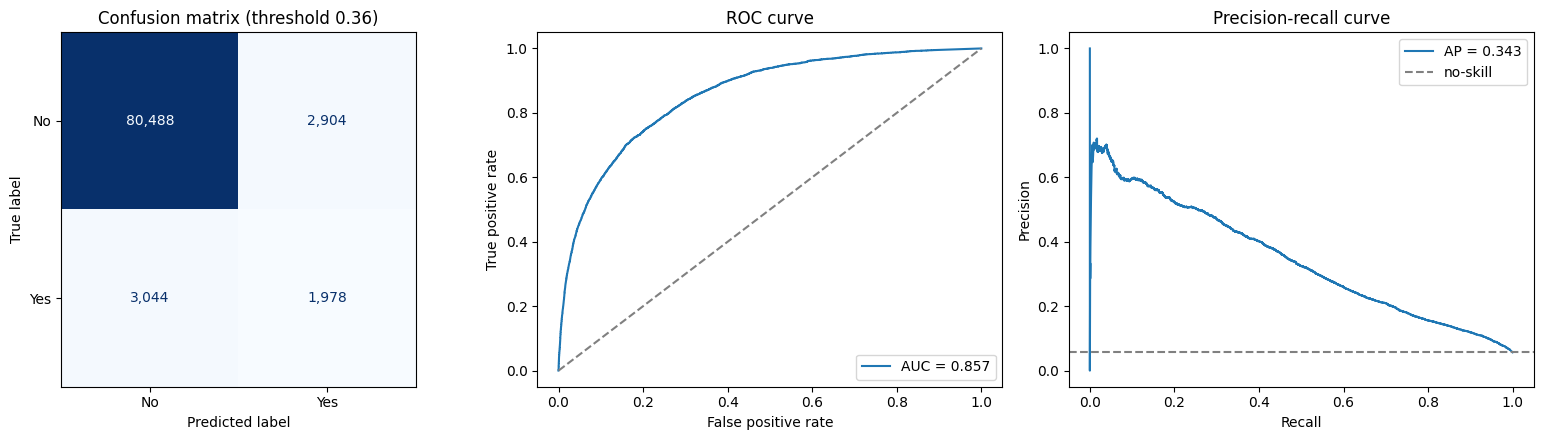

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred),
                       display_labels=["No", "Yes"]).plot(ax=axes[0], cmap="Blues", colorbar=False,
                                                          values_format=",")
axes[0].set_title(f"Confusion matrix (threshold {best_thr:.2f})")

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, label=f"AUC = {summary['ROC-AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")

pr, rc, _ = precision_recall_curve(y_test, p_test)
axes[2].plot(rc, pr, label=f"AP = {summary['PR-AUC']:.3f}")
axes[2].axhline(y_test.mean(), ls="--", color="gray", label="no-skill")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-recall curve"); axes[2].legend()

plt.tight_layout()
plt.show()

In [14]:
# precision / recall at a few operating points
ops = {}
for t in sorted({0.10, 0.20, 0.30, 0.40, 0.50, 0.60, round(float(best_thr), 3)}):
    pred = (p_test >= t).astype(int)
    ops[t] = {"Precision": precision_score(y_test, pred, zero_division=0),
              "Recall": recall_score(y_test, pred),
              "F1": f1_score(y_test, pred),
              "Flagged %": pred.mean() * 100}
pd.DataFrame(ops).T.round(3)

,Precision,Recall,F1,Flagged %
0.10,0.146,0.829,0.249,32.133
0.20,0.234,0.643,0.343,15.615
0.30,0.340,0.480,0.398,8.026
0.36,0.405,0.394,0.399,5.515
0.40,0.439,0.337,0.381,4.355
0.50,0.516,0.207,0.295,2.277
0.60,0.591,0.096,0.165,0.921


## Notes

- KNN has no built-in feature importance, and SHAP on KNN is very slow (every explanation needs neighbor searches over the training set). For interpretability, the tree models and logistic regression are the better candidates.
- Prediction cost grows with the training set, so KNN is the slowest model here to score new people, even though "training" is instant.
- Tuning used a 20k stratified subset of the training split; the final model was refit on all training rows. If the best k is the largest one tried, a bigger k might do better.
- All of this is self-reported survey data about a past diagnosis. It says nothing about future risk and isn't meant for clinical use.
- Everything tuned or chosen (resampling, k, weights, threshold) used train/validation data only. The test set was scored once at the end.
- Not done here: subgroup fairness checks (race, sex, age, income) and SHAP, both listed in the project overview for the final milestone.